# 🏠 Tashkent House Price Prediction (Machine Learning)

## 📌 Project Overview
This project is built using the **CRISP-DM** (Cross-Industry Standard Process for Data Mining) methodology. The goal is to predict real estate prices in Tashkent based on property parameters (location, rooms, size, etc.) using Machine Learning regression models.

## 🛠 Tech Stack
* **Language:** Python
* **Data Manipulation:** Pandas, NumPy
* **Visualization:** Matplotlib, Seaborn
* **ML Models:** Scikit-learn (Linear Regression, Random Forest, Gradient Boosting)

## 1️⃣ Business Understanding
Real estate agencies and buyers need a fast and accurate way to estimate property values. This model helps determine a fair market price based on historical data, saving time and reducing human error.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
sns.set_palette("viridis")
pd.set_option('display.max_columns', None)

## 2️⃣ Data Understanding
Loading the dataset and performing Exploratory Data Analysis (EDA).

In [2]:
url = 'https://raw.githubusercontent.com/anvarnarz/praktikum_datasets/main/housing_data_08-02-2021.csv'
df = pd.read_csv(url)
display(df.head())

,location,district,rooms,size,level,max_levels,price
0,"город Ташкент, Юнусабадский район, Юнусабад 8-...",Юнусабадский,3,57,4,4,52000
1,"город Ташкент, Яккасарайский район, 1-й тупик ...",Яккасарайский,2,52,4,5,56000
2,"город Ташкент, Чиланзарский район, Чиланзар 2-...",Чиланзарский,2,42,4,4,37000
3,"город Ташкент, Чиланзарский район, Чиланзар 9-...",Чиланзарский,3,65,1,4,49500
4,"город Ташкент, Чиланзарский район, площадь Актепа",Чиланзарский,3,70,3,5,55000


In [3]:
print("=== Dataset Info ===")
df.info()

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Numerical Statistics ===")
display(df.describe())

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   location    7565 non-null   str  
 1   district    7565 non-null   str  
 2   rooms       7565 non-null   int64
 3   size        7565 non-null   str  
 4   level       7565 non-null   int64
 5   max_levels  7565 non-null   int64
 6   price       7565 non-null   str  
dtypes: int64(3), str(4)
memory usage: 413.8 KB

=== Missing Values ===
location      0
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
dtype: int64

=== Numerical Statistics ===


,rooms,level,max_levels
count,7565.000000,7565.000000,7565.000000
mean,2.625644,3.699273,6.038202
std,1.085201,2.237275,2.613271
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,5.000000
75%,3.000000,5.000000,9.000000
max,10.000000,19.000000,25.000000


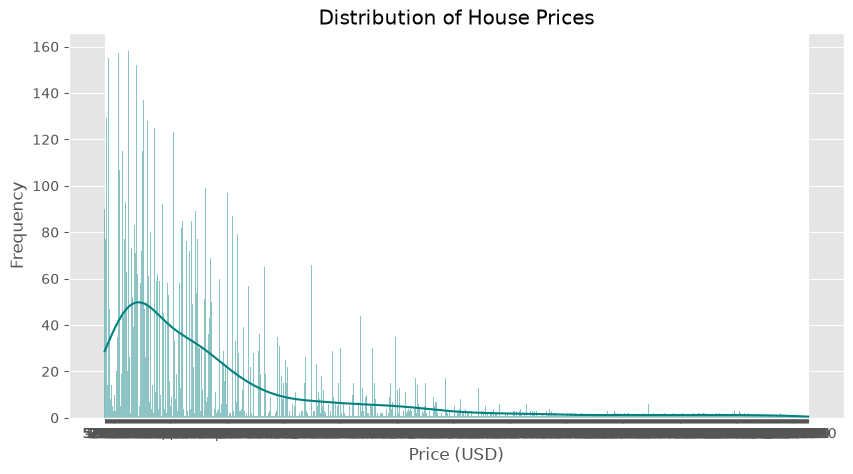

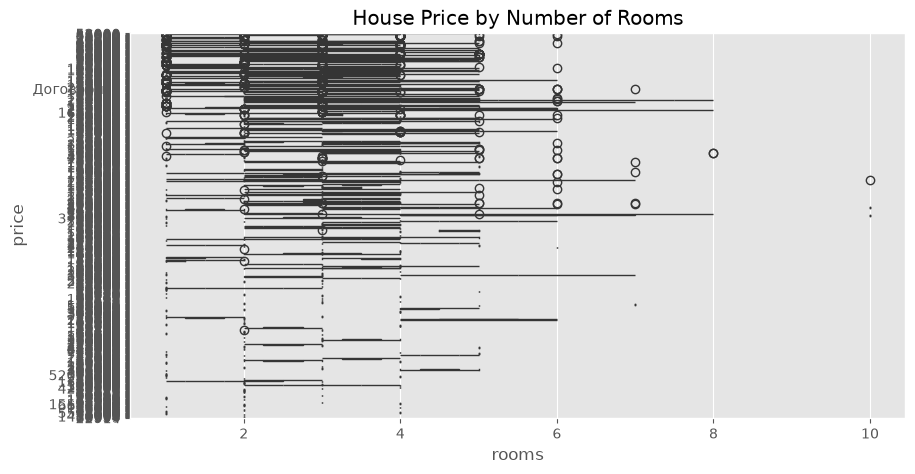

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True, color='teal')
plt.title("Distribution of House Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(x='rooms', y='price', data=df)
plt.title("House Price by Number of Rooms")
plt.show()

## 3️⃣ Data Preparation
**Key Steps:**
1. Clean `size` and `price` columns (convert to numeric, handle non-numeric values like "Договорная").
2. Remove outliers (extreme price values).
3. Apply **One-Hot Encoding** for `location` and `district` (better than Label Encoding for regression).
4. Split into Train and Test sets.

In [5]:
from sklearn.model_selection import train_test_split

df_clean = df.copy()

# 1. Tozalash
df_clean['size'] = pd.to_numeric(df_clean['size'], errors='coerce')
df_clean['size'] = df_clean['size'].fillna(df_clean['size'].mean())
df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')
df_clean = df_clean.dropna(subset=['price'])

# 2. Outlierlarni tozalash (narxi 1% dan past va 99% dan yuqori bo'lganlarni olib tashlash)
Q1 = df_clean['price'].quantile(0.01)
Q3 = df_clean['price'].quantile(0.99)
df_clean = df_clean[(df_clean['price'] >= Q1) & (df_clean['price'] <= Q3)]

# 3. ONE-HOT ENCODING (LabelEncoder o'rniga)
df_clean = pd.get_dummies(df_clean, columns=['location', 'district'], drop_first=True)

# 4. X va y
X = df_clean.drop('price', axis=1)
y = df_clean['price']

# 5. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Data shape after cleaning: {df_clean.shape}")
print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

Data shape after cleaning: (7322, 1554)
Training set: (5857, 1553)
Testing set: (1465, 1553)


## 4️⃣ Modeling
Training 3 models to compare performance:
1. **Linear Regression** (Baseline)
2. **Random Forest Regressor**
3. **Gradient Boosting Regressor** (Usually best for tabular data)

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 2. Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# 3. Gradient Boosting
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

print("All models trained successfully!")

All models trained successfully!


## 5️⃣ Evaluation
Comparing models using MAE, RMSE, and R2 Score.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    print(f"--- {model_name} ---")
    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"R2 Score: {r2:.4f} ({r2*100:.2f}% accuracy)\n")

evaluate_model(y_test, lr_pred, "Linear Regression")
evaluate_model(y_test, rf_pred, "Random Forest")
evaluate_model(y_test, gb_pred, "Gradient Boosting")

--- Linear Regression ---
MAE:  $14,272.59
RMSE: $22,910.68
R2 Score: 0.5495 (54.95% accuracy)

--- Random Forest ---
MAE:  $8,284.10
RMSE: $15,590.87
R2 Score: 0.7914 (79.14% accuracy)

--- Gradient Boosting ---
MAE:  $10,924.41
RMSE: $17,388.99
R2 Score: 0.7405 (74.05% accuracy)



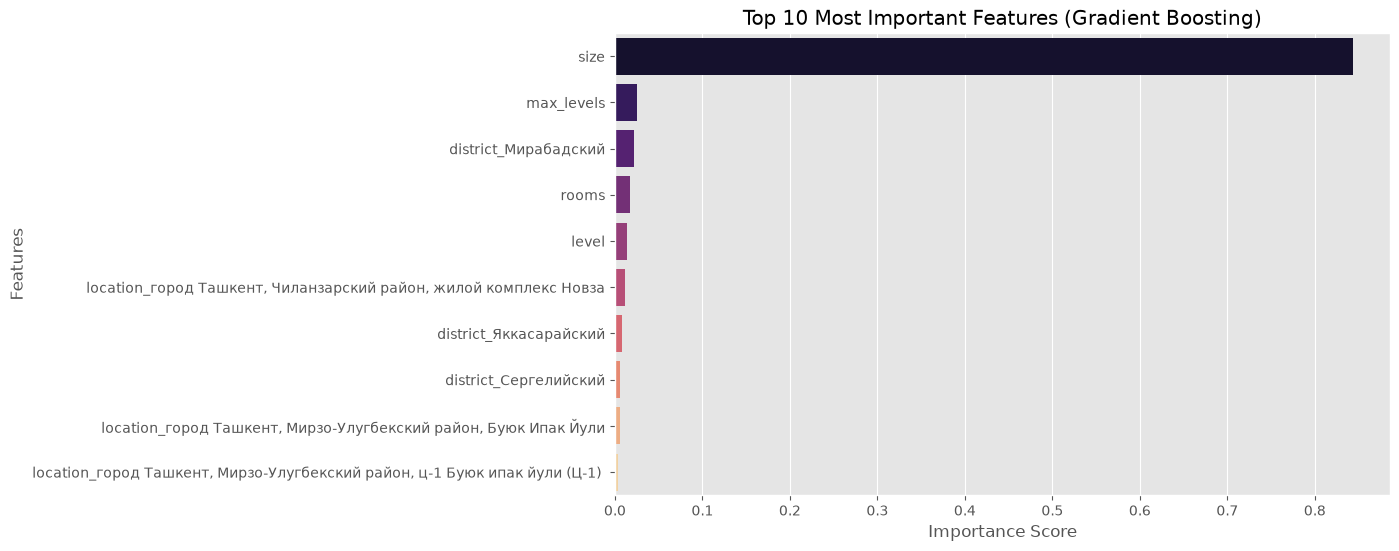

In [9]:
# Gradient Boosting modelidan eng muhim 10 ta omilni olamiz
feature_importances = pd.DataFrame(gb_model.feature_importances_,
                                   index = X_train.columns,
                                   columns=['importance']).sort_values('importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.importance, y=feature_importances.index, palette='magma')
plt.title("Top 10 Most Important Features (Gradient Boosting)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

## 6️⃣ Deployment
Saving the best-performing model (Gradient Boosting) to disk for future use.

In [10]:
import pickle

# Save the best model
with open('gradient_boosting_house_price_model.pkl', 'wb') as file:
    pickle.dump(gb_model, file)

print("Model successfully saved as 'gradient_boosting_house_price_model.pkl'!")

Model successfully saved as 'gradient_boosting_house_price_model.pkl'!
